# ==============================================================================
# BÀI TẬP 1: XÂY DỰNG & DEBUG VANILLA GAN TRÊN FASHION-MNIST
# ==============================================================================

### 🎯 Mục tiêu bài học:
1. **Cơ chế đối kháng (Adversarial Training):** Nắm vững trò chơi minimax giữa Generator ($G$) và Discriminator ($D$).
2. **Kiến trúc mạng Fully Connected (MLP):** Thiết kế mạng sinh và mạng phân biệt chuẩn xác theo đề bài.
3. **Mẹo Nonsaturating Game:** Hiểu và cài đặt mục tiêu huấn luyện $\max \log D(G(z))$ nhằm triệt tiêu hiện tượng triệt tiêu đạo hàm (vanishing gradient) trong giai đoạn đầu huấn luyện.
4. **Kiểm soát chất lượng sinh mẫu:** Cố định vector nhiễu $z_{fixed} \in \mathbb{R}^{64 \times 100}$ để theo dõi trực quan quá trình hình thành nét vẽ qua từng epoch.

In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

# Thiết lập seed cố định để đảm bảo tính tái lập (Reproducibility)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Thiết bị thực thi: {device}")

[+] Thiết bị thực thi: cuda


In [2]:
# ==============================================================================
# 1. CHUẨN BỊ DỮ LIỆU FASHION-MNIST
# Chuẩn hóa về [-1, 1] phù hợp với hàm kích hoạt Tanh ở đầu ra Generator
# ==============================================================================
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) # Ánh xạ [0, 1] -> [-1, 1]
])

train_dataset = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, drop_last=True)

print(f"[+] Số lượng ảnh huấn luyện: {len(train_dataset):,} mẫu (10 lớp quần áo, giày dép...)")

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 32.8k/26.4M [00:00<02:44, 161kB/s]

  0%|          | 65.5k/26.4M [00:00<03:33, 124kB/s]

  0%|          | 98.3k/26.4M [00:01<05:06, 86.0kB/s]

  1%|          | 164k/26.4M [00:01<02:54, 151kB/s]  

...

 84%|████████▍ | 3.74M/4.42M [00:02<00:00, 3.45MB/s]

100%|██████████| 4.42M/4.42M [00:02<00:00, 2.09MB/s]

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 5.15MB/s]

[+] Số lượng ảnh huấn luyện: 60,000 mẫu (10 lớp quần áo, giày dép...)


In [3]:
# ==============================================================================
# 2. XÂY DỰNG KIẾN TRÚC GENERATOR (G) VÀ DISCRIMINATOR (D)
# ==============================================================================

class Generator(nn.Module):
    """
    Generator: z ~ N(0, I) in R^100 -> Tầng Linear + LeakyReLU -> Tanh in [-1, 1] in R^784
    """
    def __init__(self, latent_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, 784),
            nn.Tanh() # Đưa toàn bộ pixel về khoảng [-1, 1]
        )

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    """
    Discriminator: Nhận ảnh phẳng 784 -> Xuất ra logit nhị phân (được kết hợp với BCEWithLogitsLoss)
    """
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.net(x)

# Khởi tạo mạng
latent_dim = 100
netG = Generator(latent_dim).to(device)
netD = Discriminator().to(device)

# Hàm mất mát kết hợp log-sum-exp ổn định số học
criterion = nn.BCEWithLogitsLoss()

# Optimizer Adam theo khuyến nghị của DCGAN / Vanilla GAN (lr=2e-4, betas=(0.5, 0.999))
optG = torch.optim.Adam(netG.parameters(), lr=0.0002, betas=(0.5, 0.999))
optD = torch.optim.Adam(netD.parameters(), lr=0.0002, betas=(0.5, 0.999))

# Cố định 64 vector nhiễu để theo dõi chất lượng ảnh sinh qua từng epoch
fixed_noise = torch.randn(64, latent_dim, device=device)
print("[+] Đã khởi tạo Generator, Discriminator và fixed_noise thành công!")

[+] Đã khởi tạo Generator, Discriminator và fixed_noise thành công!


In [4]:
# ==============================================================================
# 3. VÒNG LẶP HUẤN LUYỆN ĐỐI KHÁNG (ADVERSARIAL TRAINING LOOP)
# ==============================================================================
EPOCHS = 20
d_losses, g_losses = [], []
saved_samples = {}

print("=" * 70)
print("BẮT ĐẦU HUẤN LUYỆN VANILLA GAN TRÊN FASHION-MNIST")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):
    netD.train()
    netG.train()
    total_d_loss = 0.0
    total_g_loss = 0.0

    for real_images, _ in train_loader:
        b_size = real_images.size(0)
        real_images = real_images.view(b_size, -1).to(device)

        real_labels = torch.ones(b_size, 1, device=device)
        fake_labels = torch.zeros(b_size, 1, device=device)

        # ----------------------------------------------------------------------
        # (1) CẬP NHẬT DISCRIMINATOR: Maximize log D(x) + log(1 - D(G(z)))
        #     Tương đương: Minimize BCE(D(x), 1) + BCE(D(G(z)), 0)
        # ----------------------------------------------------------------------
        optD.zero_grad()
        
        # Loss trên ảnh thật
        out_real = netD(real_images)
        loss_d_real = criterion(out_real, real_labels)
        
        # Loss trên ảnh giả (detach G để không truyền ngược gradient vào Generator)
        noise = torch.randn(b_size, latent_dim, device=device)
        fake_images = netG(noise)
        out_fake = netD(fake_images.detach())
        loss_d_fake = criterion(out_fake, fake_labels)
        
        loss_D = loss_d_real + loss_d_fake
        loss_D.backward()
        optD.step()
        total_d_loss += loss_D.item()

        # ----------------------------------------------------------------------
        # (2) CẬP NHẬT GENERATOR: Nonsaturating Game
        #     Maximize log D(G(z)) <==> Minimize BCE(D(G(z)), 1)
        # ----------------------------------------------------------------------
        optG.zero_grad()
        out_g = netD(fake_images)
        loss_G = criterion(out_g, real_labels) # G muốn D nhầm ảnh giả thành nhãn 1 (thật)
        loss_G.backward()
        optG.step()
        total_g_loss += loss_G.item()

    avg_d = total_d_loss / len(train_loader)
    avg_g = total_g_loss / len(train_loader)
    d_losses.append(avg_d)
    g_losses.append(avg_g)

    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Loss D: {avg_d:.4f} | Loss G: {avg_g:.4f}")

    # Lưu ảnh sinh ra tại epoch 1, 5, 10, 15, 20
    if epoch == 1 or epoch % 5 == 0:
        netG.eval()
        with torch.no_grad():
            samples = netG(fixed_noise).view(-1, 1, 28, 28).cpu()
            # Chuyển từ [-1, 1] về [0, 1] để hiển thị
            samples = (samples + 1.0) / 2.0
            saved_samples[epoch] = samples

print("[+] Huấn luyện hoàn tất!")

BẮT ĐẦU HUẤN LUYỆN VANILLA GAN TRÊN FASHION-MNIST


Epoch [01/20] | Loss D: 0.9929 | Loss G: 1.0919


Epoch [02/20] | Loss D: 0.9008 | Loss G: 1.7018


Epoch [03/20] | Loss D: 0.9773 | Loss G: 1.6819


Epoch [04/20] | Loss D: 1.0643 | Loss G: 1.3822


...

Epoch [16/20] | Loss D: 1.3083 | Loss G: 0.8893


Epoch [17/20] | Loss D: 1.3139 | Loss G: 0.8765


Epoch [18/20] | Loss D: 1.3201 | Loss G: 0.8640


Epoch [19/20] | Loss D: 1.3245 | Loss G: 0.8545


Epoch [20/20] | Loss D: 1.3301 | Loss G: 0.8494
[+] Huấn luyện hoàn tất!


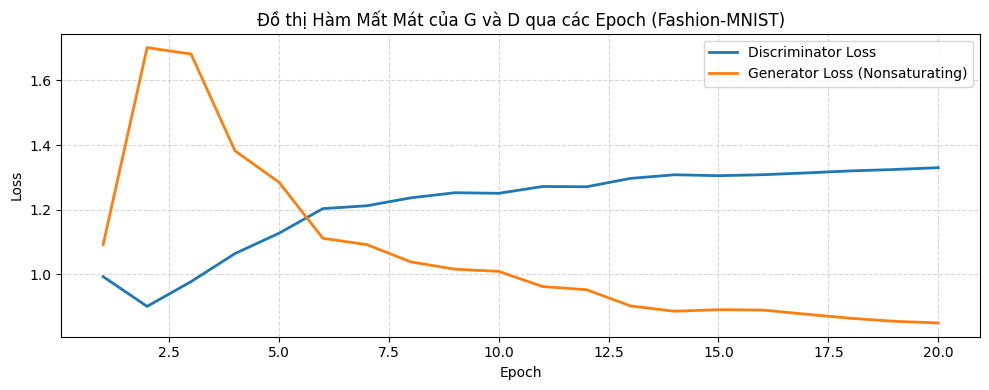

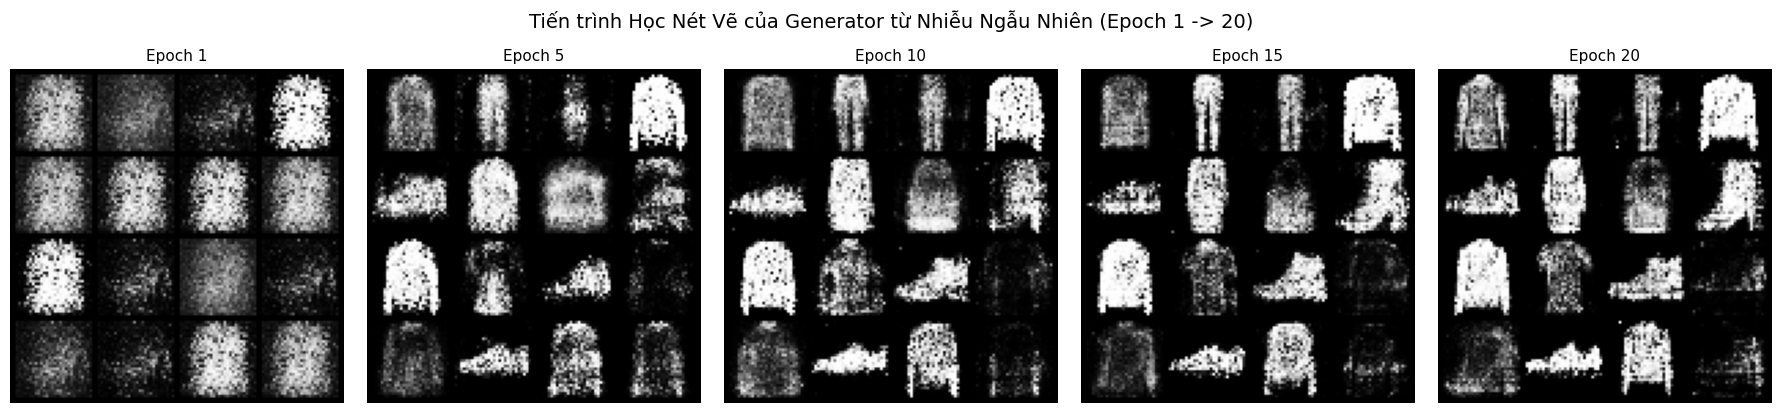

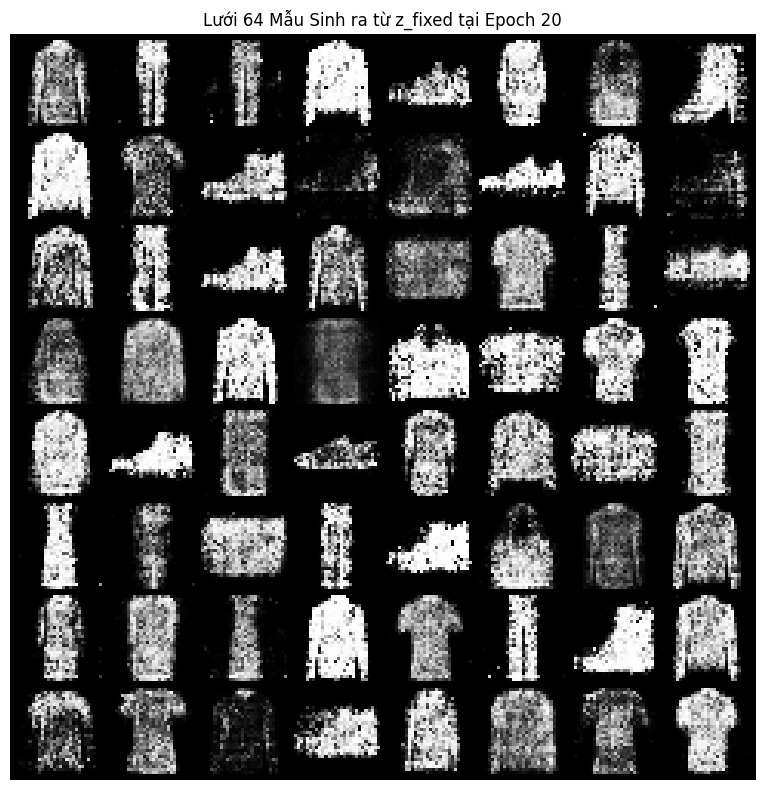

In [5]:
# ==============================================================================
# 4. ĐỒ THỊ LOSS VÀ TIẾN TRÌNH SINH ẢNH THEO THỜI GIAN
# ==============================================================================

# 1. Đồ thị Loss
plt.figure(figsize=(10, 4))
plt.plot(range(1, EPOCHS + 1), d_losses, label="Discriminator Loss", color="tab:blue", lw=2)
plt.plot(range(1, EPOCHS + 1), g_losses, label="Generator Loss (Nonsaturating)", color="tab:orange", lw=2)
plt.title("Đồ thị Hàm Mất Mát của G và D qua các Epoch (Fashion-MNIST)", fontsize=12)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Trực quan hóa tiến trình sinh ảnh qua các epoch (1, 5, 10, 15, 20)
epochs_to_show = sorted(saved_samples.keys())
fig, axes = plt.subplots(1, len(epochs_to_show), figsize=(18, 4))

for idx, ep in enumerate(epochs_to_show):
    # Lấy 16 ảnh đầu để hiển thị lưới 4x4
    grid = make_grid(saved_samples[ep][:16], nrow=4, padding=2)
    axes[idx].imshow(grid.permute(1, 2, 0).numpy(), cmap="gray")
    axes[idx].set_title(f"Epoch {ep}", fontsize=11)
    axes[idx].axis("off")

plt.suptitle("Tiến trình Học Nét Vẽ của Generator từ Nhiễu Ngẫu Nhiên (Epoch 1 -> 20)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# 3. Chi tiết lưới 64 ảnh sinh ra tại Epoch cuối cùng
plt.figure(figsize=(8, 8))
final_grid = make_grid(saved_samples[EPOCHS], nrow=8, padding=2)
plt.imshow(final_grid.permute(1, 2, 0).numpy(), cmap="gray")
plt.title(f"Lưới 64 Mẫu Sinh ra từ z_fixed tại Epoch {EPOCHS}", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()

# ==============================================================================
# 5. BÁO CÁO PHÂN TÍCH: TẠI SAO PHẢI DÙNG NONSATURATING GAME CHO GENERATOR?
# ==============================================================================

### 1. Vấn đề của hàm mục tiêu gốc (Minimax Game):
Trong công trình gốc của Goodfellow et al. (2014), bài toán tối ưu được đặt dưới dạng zero-sum game:
$$\min_G \max_D V(D, G) = \mathbb{E}_{x \sim p_{data}}[\log D(x)] + \mathbb{E}_{z \sim p_z}[\log(1 - D(G(z)))]$$

Theo công thức này, Generator cố gắng tối thiểu hóa:
$$\mathcal{L}_G^{minimax} = \log(1 - D(G(z)))$$

### 2. Hiện tượng Triệt tiêu Đạo hàm (Vanishing Gradient / Gradient Saturation):
* Ở giai đoạn đầu huấn luyện, Generator chỉ tạo ra các mảng nhiễu hạt vô nghĩa. Ngược lại, Discriminator $D$ rất dễ dàng phân biệt ảnh thật và ảnh giả, dẫn đến $D(G(z)) \approx 0$.
* Xét đạo hàm của hàm mất mát gốc theo xác suất $p = D(G(z))$:
$$\frac{d}{dp}\log(1 - p) = -\frac{1}{1 - p}$$
* Khi $p \to 0$, độ dốc đạo hàm này tiến về $-1$ (rất nhỏ và phẳng). Khi nhân với đạo hàm của hàm Sigmoid qua chuỗi vi phân (chain rule), gradient truyền về các tầng của Generator gần như bằng $0$.
* **Hậu quả:** Generator bị "đóng băng", không nhận được bất kỳ tín hiệu học tập nào để cải thiện ở những epoch đầu tiên.

### 3. Giải pháp: Mẹo Nonsaturating Heuristic Game:
Thay vì cố gắng tối thiểu hóa khả năng $D$ phát hiện ảnh giả ($\min \log(1 - D(G(z)))$), ta đổi mục tiêu sang **tối đa hóa khả năng $D$ nhầm ảnh giả thành ảnh thật**:
$$\mathcal{L}_G^{nonsaturating} = -\log D(G(z)) \quad (\text{tối thiểu hóa tiêu chuẩn})$$

* Xét đạo hàm theo $p = D(G(z))$:
$$\frac{d}{dp}(-\log p) = -\frac{1}{p}$$
* Khi $p \to 0$ (ở giai đoạn đầu), $-\frac{1}{p} \to -\infty$ $\implies$ Gradient cực lớn, cung cấp xung lực học tập mạnh mẽ giúp Generator nhanh chóng thoát khỏi vùng nhiễu để học các nét vẽ ban đầu.
* Khi $p \to 1$ (ở giai đoạn cuối, Generator sinh ảnh rất tốt), gradient giảm dần về $-1$, giúp quá trình tối ưu ổn định và hội tụ mượt mà.